# AIML Lab Exercise 10: k-Means Clustering
**Dataset:** Synthetic Mall Customers Dataset (mall_customers.csv)

This notebook applies the **k-Means algorithm** to cluster a set of customers stored in a `.CSV` file, based on their annual income and spending score. k-Means is an **unsupervised learning** algorithm — it groups the data without using any labels. The algorithm is implemented **from scratch**, the number of clusters is chosen with the **elbow method** and **silhouette score**, the result is compared with scikit-learn's `KMeans` and with the **Expectation-Maximization (EM)** algorithm (Gaussian Mixture Model), and the clustered data is saved to a new CSV file.

## 1. Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset from the CSV file

In [2]:
df = pd.read_csv('mall_customers.csv')
print("Dataset loaded successfully! Shape:", df.shape)
df.info()
display(df.head())
display(df.describe())
print("Missing values:", df.isnull().sum().sum())

Dataset loaded successfully! Shape: (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      200 non-null    int64
 1   Gender          200 non-null    str  
 2   Age             200 non-null    int64
 3   AnnualIncome_k  200 non-null    int64
 4   SpendingScore   200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,CustomerID,Gender,Age,AnnualIncome_k,SpendingScore
0,1,Male,58,33,82
1,2,Female,18,84,74
2,3,Female,37,23,72
3,4,Female,33,50,52
4,5,Female,48,82,77


,CustomerID,Age,AnnualIncome_k,SpendingScore
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,42.160000,55.910000,48.500000
std,57.879185,15.736026,27.735142,27.892651
min,1.000000,18.000000,12.000000,1.000000
25%,50.750000,28.000000,28.000000,22.000000
50%,100.500000,43.000000,52.500000,50.000000
75%,150.250000,55.000000,84.250000,76.000000
max,200.000000,69.000000,101.000000,99.000000


Missing values: 0


## 3. Exploratory data analysis

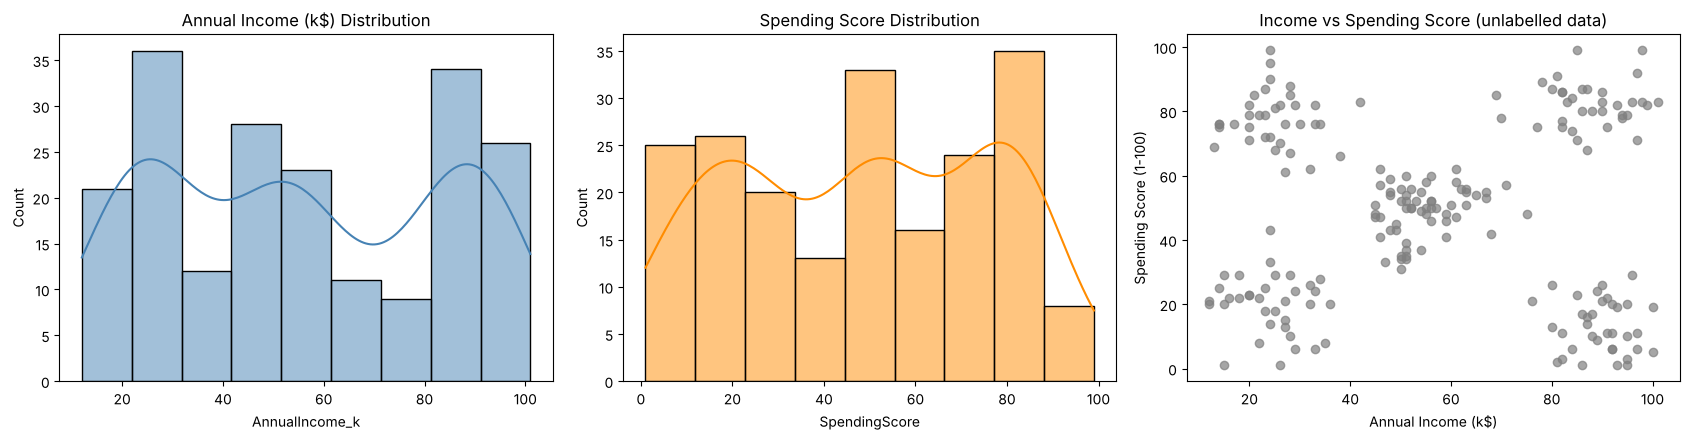

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df['AnnualIncome_k'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Annual Income (k$) Distribution')
sns.histplot(df['SpendingScore'], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Spending Score Distribution')
axes[2].scatter(df['AnnualIncome_k'], df['SpendingScore'], color='gray', alpha=0.7)
axes[2].set_xlabel('Annual Income (k$)')
axes[2].set_ylabel('Spending Score (1-100)')
axes[2].set_title('Income vs Spending Score (unlabelled data)')
plt.tight_layout()
plt.show()

**Interpretation:** The scatter plot already suggests a few natural groups of customers. k-Means should find them automatically.

## 4. Select the features and standardize them
k-Means uses Euclidean distance, so features are standardized to give them equal weight.

In [4]:
features = ['AnnualIncome_k', 'SpendingScore']
X = df[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature matrix shape:", X_scaled.shape)
print("Means after scaling:", X_scaled.mean(axis=0).round(4), " Std after scaling:", X_scaled.std(axis=0).round(4))

Feature matrix shape: (200, 2)
Means after scaling: [0. 0.]  Std after scaling: [1. 1.]


## 5. Implement the k-Means algorithm from scratch
**Algorithm:**
1. Choose *k* data points at random as the initial **centroids**.
2. **Assignment step:** assign every point to its nearest centroid (Euclidean distance).
3. **Update step:** move every centroid to the mean of the points assigned to it.
4. Repeat steps 2–3 until the centroids stop moving (convergence).

The objective minimised is the **Within-Cluster Sum of Squares (WCSS / inertia)**:

$$J = \sum_{j=1}^{k}\sum_{x_i \in C_j}\lVert x_i - \mu_j\rVert^2$$

Because the result depends on the random initial centroids, the algorithm is run several times (`n_init`) and the run with the lowest WCSS is kept.

In [5]:
def kmeans(X, k, max_iters=100, n_init=10, seed=42, tol=1e-6):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        centroids = X[rng.choice(len(X), k, replace=False)]
        history = [centroids.copy()]
        for iteration in range(max_iters):
            distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
            labels = distances.argmin(axis=1)                                   # assignment step
            new_centroids = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j]
                                      for j in range(k)])                       # update step
            history.append(new_centroids.copy())
            shift = np.linalg.norm(new_centroids - centroids)
            centroids = new_centroids
            if shift < tol:
                break
        labels = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2).argmin(axis=1)
        wcss = ((X - centroids[labels]) ** 2).sum()
        if best is None or wcss < best['wcss']:
            best = {'labels': labels, 'centroids': centroids, 'wcss': wcss,
                    'iterations': iteration + 1, 'history': history}
    return best

print("k-Means function defined.")

k-Means function defined.


## 6. Choose the number of clusters: elbow method
WCSS always decreases as *k* increases. The **elbow** — the point after which adding more clusters gives only a small improvement — is a good choice for *k*.

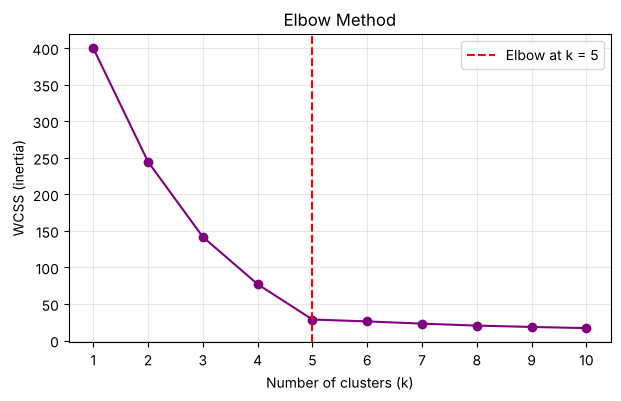

k,1,2,3,4,5,6,7,8,9,10
WCSS,400.0,244.56,141.74,77.06,28.75,26.16,23.13,20.43,18.6,17.0


In [6]:
k_values = range(1, 11)
wcss = [kmeans(X_scaled, k)['wcss'] for k in k_values]

plt.figure(figsize=(7, 4))
plt.plot(k_values, wcss, 'o-', color='purple')
plt.axvline(5, color='red', linestyle='--', label='Elbow at k = 5')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (inertia)')
plt.title('Elbow Method')
plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)
plt.show()
display(pd.DataFrame({'k': list(k_values), 'WCSS': np.round(wcss, 2)}).set_index('k').T)

## 7. Choose the number of clusters: silhouette score
The silhouette score (between −1 and 1) measures how similar a point is to its own cluster compared with other clusters. **Higher is better.**

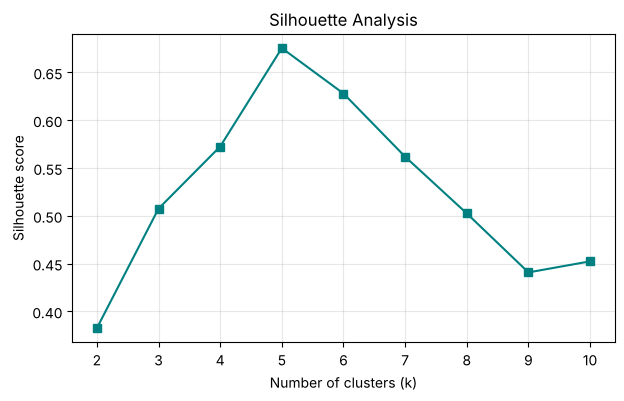

Silhouette scores: {2: 0.3826, 3: 0.5076, 4: 0.5725, 5: 0.6755, 6: 0.628, 7: 0.5619, 8: 0.5026, 9: 0.4409, 10: 0.4524}
Best k according to silhouette score: 5


In [7]:
sil_scores = {k: silhouette_score(X_scaled, kmeans(X_scaled, k)['labels']) for k in range(2, 11)}
best_k = max(sil_scores, key=sil_scores.get)

plt.figure(figsize=(7, 4))
plt.plot(list(sil_scores), list(sil_scores.values()), 's-', color='teal')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Analysis')
plt.grid(alpha=0.3)
plt.show()
print("Silhouette scores:", {k: round(v, 4) for k, v in sil_scores.items()})
print("Best k according to silhouette score:", best_k)

## 8. Apply k-Means with the chosen number of clusters (k = 5)

In [8]:
k = 5
result = kmeans(X_scaled, k)
labels = result['labels']
centroids = scaler.inverse_transform(result['centroids'])      # back to original units

print(f"Converged in {result['iterations']} iterations")
print(f"Final WCSS: {result['wcss']:.4f}")
print(f"Silhouette score: {silhouette_score(X_scaled, labels):.4f}")
print("Cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())
display(pd.DataFrame(centroids, columns=features).round(2).rename_axis('Cluster'))

Converged in 6 iterations
Final WCSS: 28.7490
Silhouette score: 0.6755
Cluster sizes: {0: 60, 1: 35, 2: 35, 3: 35, 4: 35}


,AnnualIncome_k,SpendingScore
Cluster,,
0,54.52,49.15
1,24.09,19.89
2,24.89,77.66
3,89.60,13.14
4,87.46,82.20


## 9. Visualize the clusters and centroids

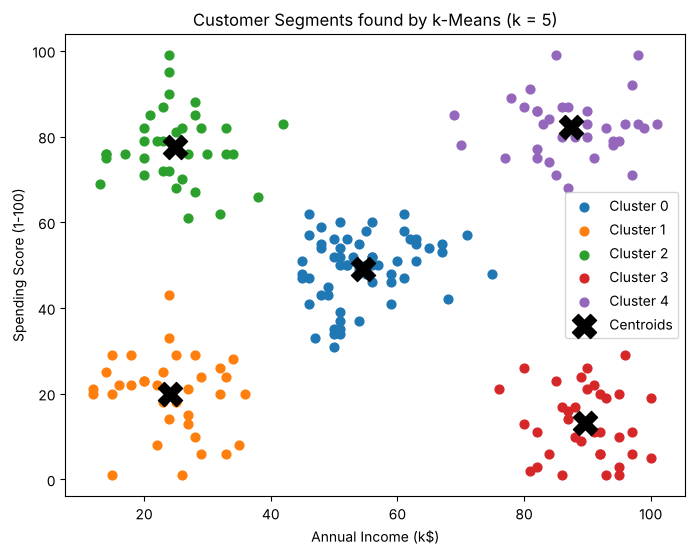

In [9]:
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
plt.figure(figsize=(8, 6))
for j in range(k):
    plt.scatter(X[labels == j, 0], X[labels == j, 1], s=40, color=colors[j], label=f'Cluster {j}')
plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c='black', marker='X', label='Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segments found by k-Means (k = 5)')
plt.legend()
plt.show()

## 10. Visualize how the centroids move during the iterations

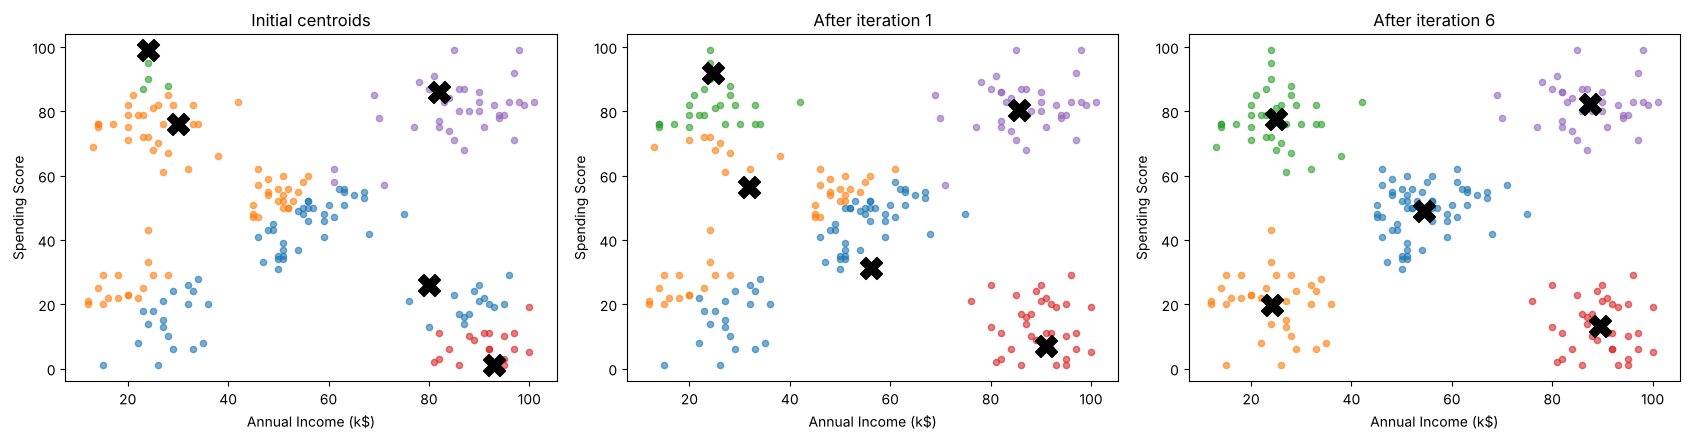

In [10]:
history = [scaler.inverse_transform(c) for c in result['history']]
steps = [0, 1, len(history) - 1]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, step in zip(axes, steps):
    c = history[step]
    step_labels = np.linalg.norm(X[:, None, :] - c[None, :, :], axis=2).argmin(axis=1)
    for j in range(k):
        ax.scatter(X[step_labels == j, 0], X[step_labels == j, 1], s=20, color=colors[j], alpha=0.6)
    ax.scatter(c[:, 0], c[:, 1], s=250, c='black', marker='X')
    ax.set_title('Initial centroids' if step == 0 else f'After iteration {step}')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score')
plt.tight_layout()
plt.show()

## 11. Compare with scikit-learn's KMeans
The **Adjusted Rand Index (ARI)** compares two clusterings: 1.0 means they are identical (cluster numbers may differ).

In [11]:
sk_kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
sk_labels = sk_kmeans.fit_predict(X_scaled)

print(f"WCSS (from scratch) : {result['wcss']:.4f}")
print(f"WCSS (scikit-learn) : {sk_kmeans.inertia_:.4f}")
print(f"Adjusted Rand Index between the two clusterings: {adjusted_rand_score(labels, sk_labels):.4f}")

WCSS (from scratch) : 28.7490
WCSS (scikit-learn) : 28.7490
Adjusted Rand Index between the two clusterings: 1.0000


## 12. Cluster profiling: interpret the customer segments

In [12]:
df['Cluster'] = labels

def describe_segment(income, score):
    inc = 'Low income' if income < 40 else 'High income' if income > 70 else 'Average income'
    spend = 'low spending' if score < 35 else 'high spending' if score > 65 else 'average spending'
    return f"{inc}, {spend}"

profile = df.groupby('Cluster').agg(Customers=('CustomerID', 'count'),
                                    Avg_Income_k=('AnnualIncome_k', 'mean'),
                                    Avg_SpendingScore=('SpendingScore', 'mean'),
                                    Avg_Age=('Age', 'mean')).round(1)
profile['Segment'] = [describe_segment(i, s) for i, s in zip(profile['Avg_Income_k'], profile['Avg_SpendingScore'])]
display(profile)

,Customers,Avg_Income_k,Avg_SpendingScore,Avg_Age,Segment
Cluster,,,,,
0,60,54.5,49.2,43.1,"Average income, average spending"
1,35,24.1,19.9,41.4,"Low income, low spending"
2,35,24.9,77.7,42.6,"Low income, high spending"
3,35,89.6,13.1,44.0,"High income, low spending"
4,35,87.5,82.2,38.9,"High income, high spending"


**Interpretation:** The five clusters correspond to clear marketing segments, e.g. *high income, high spending* customers are the best target for premium offers, while *high income, low spending* customers might be attracted with special promotions.

## 13. Compare k-Means with the EM algorithm (Gaussian Mixture Model)
The **Expectation-Maximization (EM)** algorithm fits a mixture of Gaussians. Unlike k-Means (hard assignment of each point to one cluster), EM gives a **soft assignment** — the probability that each point belongs to each cluster.
- **E-step:** compute the probability of each point belonging to each Gaussian.
- **M-step:** update the mean, covariance and weight of each Gaussian using these probabilities.

Silhouette score - k-Means: 0.6755
Silhouette score - EM (GMM): 0.6755
Adjusted Rand Index between k-Means and EM: 1.0000

Soft cluster probabilities of the 5 customers with the most uncertain assignment (EM):


,AnnualIncome_k,SpendingScore,P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4)
182,38,66,0.0000,0.0373,0.0,0.9627,0.0000
119,34,28,0.0000,0.0146,0.0,0.0000,0.9854
116,46,62,0.0000,0.9901,0.0,0.0099,0.0000
89,24,43,0.0000,0.0035,0.0,0.0060,0.9905
161,70,78,0.9911,0.0089,0.0,0.0000,0.0000


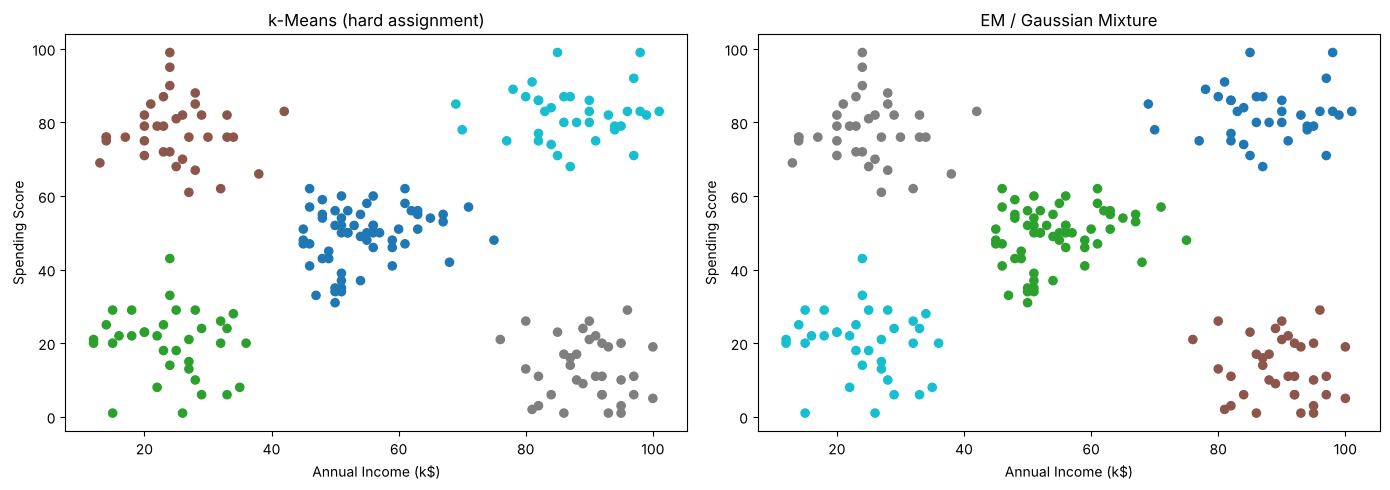

In [13]:
gmm = GaussianMixture(n_components=k, random_state=42)
em_labels = gmm.fit_predict(X_scaled)
em_probs = gmm.predict_proba(X_scaled)

print(f"Silhouette score - k-Means: {silhouette_score(X_scaled, labels):.4f}")
print(f"Silhouette score - EM (GMM): {silhouette_score(X_scaled, em_labels):.4f}")
print(f"Adjusted Rand Index between k-Means and EM: {adjusted_rand_score(labels, em_labels):.4f}")
# Customers lying between clusters get split probabilities instead of a hard 0/1 assignment
uncertain = np.argsort(em_probs.max(axis=1))[:5]
print("\nSoft cluster probabilities of the 5 customers with the most uncertain assignment (EM):")
soft = pd.DataFrame(em_probs[uncertain], columns=[f'P(cluster {j})' for j in range(k)], index=uncertain).round(4)
soft.insert(0, 'AnnualIncome_k', X[uncertain, 0])
soft.insert(1, 'SpendingScore', X[uncertain, 1])
display(soft)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, title in [(axes[0], labels, 'k-Means (hard assignment)'), (axes[1], em_labels, 'EM / Gaussian Mixture')]:
    ax.scatter(X[:, 0], X[:, 1], c=lab, cmap='tab10', s=35)
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score')
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 14. Save the clustered dataset as a new CSV file

In [14]:
df['Segment'] = df['Cluster'].map(profile['Segment'])
df.to_csv('mall_customers_clustered.csv', index=False)
print("Clustered dataset saved as 'mall_customers_clustered.csv'")
display(df.head())

Clustered dataset saved as 'mall_customers_clustered.csv'


,CustomerID,Gender,Age,AnnualIncome_k,SpendingScore,Cluster,Segment
0,1,Male,58,33,82,2,"Low income, high spending"
1,2,Female,18,84,74,4,"High income, high spending"
2,3,Female,37,23,72,2,"Low income, high spending"
3,4,Female,33,50,52,0,"Average income, average spending"
4,5,Female,48,82,77,4,"High income, high spending"


## 15. Documentation summary
1. Loaded the customer data from a CSV file and explored it
2. Selected and standardized the features (annual income and spending score)
3. Implemented the k-Means algorithm from scratch (random initialisation, assignment step, update step, convergence check, multiple restarts)
4. Chose the number of clusters using the elbow method and the silhouette score (k = 5)
5. Clustered the data, visualized the clusters and centroids, and showed how centroids move during the iterations
6. Verified the result against scikit-learn's `KMeans`
7. Profiled and interpreted each customer segment
8. Compared k-Means with the EM algorithm (Gaussian Mixture Model)
9. Saved the clustered dataset as `mall_customers_clustered.csv`

**Result:** The k-Means algorithm was applied successfully to cluster the customer data stored in a CSV file into 5 meaningful segments.